# **Projet Apprentissage de Statistique**
Yester  MKRTCHYAN

## Introduction 

L’analyse des chromosomes joue un rôle important dans le diagnostic de certaines anomalies chromosomiques, notamment dans le cadre d’études liées à la fertilité. À partir d’images de chromosomes obtenues par imagerie microscopique, il est possible d’extraire un profil d’intensité unidimensionnel représentant les variations de bandes claires et sombres le long du chromosome. Chaque chromosome peut ainsi être résumé sous la forme d’un signal 1D discrétisé sur 100 points.

L’objectif de ce projet est d’étudier la possibilité de reconnaître automatiquement la classe d’un chromosome à partir de ce profil d’intensité. Le problème est formulé comme un problème de classification supervisée à 22 classes, chaque classe correspondant à un type de chromosome. Pour cela, plusieurs approches seront étudiées et comparées. Dans un premier temps, une méthode de forêts aléatoires sera appliquée directement aux profils bruts. L’impact de l’intensité des déformations appliquées aux signaux sera également analysé. Dans un second temps, l’effet d’une réduction de dimension sera étudié afin d’évaluer si une représentation plus compacte des données permet d’améliorer les performances de classification. Enfin, des représentations fonctionnelles des profils, basées sur des décompositions en séries de Fourier et en B-splines, seront utilisées afin de comparer leurs performances à celles obtenues avec les données brutes.

### **1: Développer une règle de classification qui prédisent target_class en fonction de result en utilisant des forets aléatoires. Etudier la qualité de la règle obtenue en fonction de l'intensité de la déformation subie.**


### Préparation des données

Commencons par la préparation des données. Le jeu de données contient la classe du chromosome (target_class), le niveau de déformation (strength) ainsi qu’un profil 1D (result) représentant le chromosome discrétisé sur 100 points. La colonne result étant stockée sous forme de chaîne de caractères dans le fichier CSV, une étape de conversion est nécessaire afin de transformer chaque profil en vecteur numérique exploitable par les méthodes d’apprentissage. La fonction convert_to_array permet ainsi de convertir chaque chaîne en tableau NumPy. Après conversion, les profils sont regroupés dans une matrice X∈R 110000×100, ce qui signifie que le jeu de données contient 110000 chromosomes simulés décrits chacun par 100 valeurs d’intensité. Chaque ligne correspond à un chromosome simulé et chaque colonne à une position le long du profil. La variable cible utilisée pour la classification est target_class, ce qui conduit à un problème de classification supervisée à 22 classes. La variable strength n’est pas utilisée pour l’apprentissage du modèle car elle ne serait pas disponible en situation réelle ; elle est uniquement conservée afin d’étudier l’impact de la déformation sur les performances de classification.

In [ ]:

# Importation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ast

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# Chargement des données
simulated_profiles = pd.read_csv("simulated_profiles.csv")


# Conversion de la colonne result
def convert_to_array(s):
    try:
        # remplacement des espaces par des virgules
        s_clean = s.replace(" ", ",")

        # conversion en tableau numpy
        return np.array(ast.literal_eval(s_clean))

    except (ValueError, SyntaxError):

        return np.array([])

# application de la conversion
simulated_profiles["result"] = (
    simulated_profiles["result"]
    .apply(convert_to_array)
)


# Construction des variables


# matrice des profils
X = np.vstack(simulated_profiles["result"].values)

# variable cible
y = simulated_profiles["target_class"]

# intensité de déformation
strength = simulated_profiles["strength"]

print("Dimensions de X :", X.shape)
print("Nombre de classes :", y.nunique())

Dimensions de X : (110000, 100)
Nombre de classes : 22


Quelques profils chromosomiques ont été représentés graphiquement afin de visualiser la structure des signaux. On observe des variations régulières d’intensité le long du chromosome, correspondant aux alternances de bandes claires et sombres. Les différents profils observés possèdent une structure globale similaire mais présentent néanmoins certaines différences locales, ce qui laisse penser que les informations contenues dans les signaux pourraient permettre de distinguer les différentes classes de chromosomes.

Les données ont ensuite été séparées en deux ensembles : un ensemble d’apprentissage représentant 80 % des observations (88000 profils) et un ensemble de test représentant 20 % des observations (22000 profils). La séparation a été réalisée à l’aide d’un échantillonnage stratifié sur target_class afin de conserver les proportions des différentes classes dans les deux ensembles. L’ensemble d’apprentissage est utilisé pour entraîner le modèle, tandis que l’ensemble de test permet d’évaluer ses performances sur des données non vues pendant l’apprentissage.

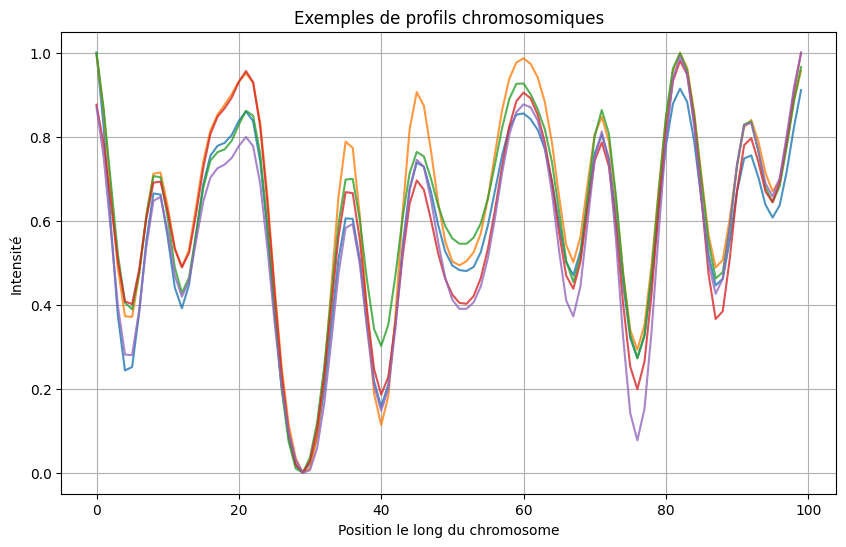

Taille train : (88000, 100)
Taille test : (22000, 100)


In [3]:
# Visualisation de quelques profils
plt.figure(figsize=(10,6))

for i in range(5):
    plt.plot(X[i], alpha=0.8)

plt.title("Exemples de profils chromosomiques")
plt.xlabel("Position le long du chromosome")
plt.ylabel("Intensité")
plt.grid(True)
plt.show()


# Séparation train/test
X_train, X_test, y_train, y_test, s_train, s_test = train_test_split(
    X,
    y,
    strength,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Taille train :", X_train.shape)
print("Taille test :", X_test.shape)


### Construction de la Random Forest

Pour réaliser la classification des chromosomes, une méthode de forêts aléatoires (Random Forest) a été utilisée. Cette méthode repose sur la construction d’un grand nombre d’arbres de décision entraînés sur des sous-échantillons aléatoires des données, la prédiction finale étant obtenue par vote majoritaire des différents arbres. Les forêts aléatoires sont particulièrement adaptées à ce problème car elles gèrent efficacement les relations non linéaires entre variables, sont robustes au bruit et au surapprentissage, et fonctionnent bien avec des données de dimension relativement élevée ainsi qu’avec des problèmes de classification multi-classes. Le paramètre n_estimators=300 signifie que la forêt est composée de 300 arbres de décision, ce qui permet d’obtenir des prédictions plus stables. Le paramètre max_features="sqrt" indique qu’à chaque séparation d’un arbre, seule une partie des variables est sélectionnée aléatoirement, ce qui favorise la diversité des arbres et améliore les performances globales du modèle. Le paramètre random_state=42 permet d’assurer la reproductibilité des résultats, tandis que n_jobs=-1 autorise l’utilisation de l’ensemble des cœurs du processeur afin d’accélérer les calculs. Le modèle est ensuite entraîné sur l’ensemble d’apprentissage à l’aide de la méthode fit, puis des prédictions sont réalisées sur l’ensemble de test grâce à la méthode predict.

In [4]:
# Construction de la Random Forest
rf = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)


# Entraînement
rf.fit(X_train, y_train)


# Prédictions
y_pred = rf.predict(X_test)

### Evalutation Globale

Afin d’évaluer les performances globales du modèle de classification, plusieurs métriques ont été calculées à l’aide des fonctions de la bibliothèque scikit-learn. L’accuracy globale obtenue est de 0.9987, soit environ 99,87 %, ce qui signifie que le modèle prédit correctement la quasi-totalité des observations du jeu de test. Le classification report fournit ensuite des indicateurs détaillés pour chaque classe : la précision (precision), le rappel (recall) et le score F1 (f1-score). Les valeurs obtenues sont très proches de 1.00 pour l’ensemble des classes, ce qui montre que le modèle distingue efficacement les différentes catégories avec très peu d’erreurs de classification. Enfin, la matrice de confusion permet de visualiser les prédictions correctes et incorrectes du modèle. Les valeurs élevées situées sur la diagonale principale indiquent que la majorité des échantillons sont correctement classés dans leur classe réelle, tandis que les très faibles valeurs hors diagonale montrent que les erreurs sont rares. Ces résultats démontrent donc que le modèle possède d’excellentes performances et une très grande capacité de généralisation sur les données testées.


On observe néanmoins quelques confusions mineures entre certaines classes, notamment pour les classes 14 et 16, mais celles-ci restent très limitées par rapport au nombre total d’observations. Cela confirme la robustesse et la fiabilité du modèle entraîné.


Accuracy globale :
0.9987272727272727

Classification report :
              precision    recall  f1-score   support

           1       1.00      1.00      1.00      1000
           2       1.00      1.00      1.00      1000
           3       1.00      1.00      1.00      1000
           4       1.00      1.00      1.00      1000
           5       1.00      1.00      1.00      1000
           6       1.00      1.00      1.00      1000
           7       1.00      1.00      1.00      1000
           8       1.00      1.00      1.00      1000
           9       1.00      1.00      1.00      1000
          10       1.00      1.00      1.00      1000
          11       1.00      1.00      1.00      1000
          12       1.00      1.00      1.00      1000
          13       1.00      1.00      1.00      1000
          14       1.00      0.99      1.00      1000
          15       1.00      1.00      1.00      1000
          16       1.00      0.99      1.00      1000
          17     

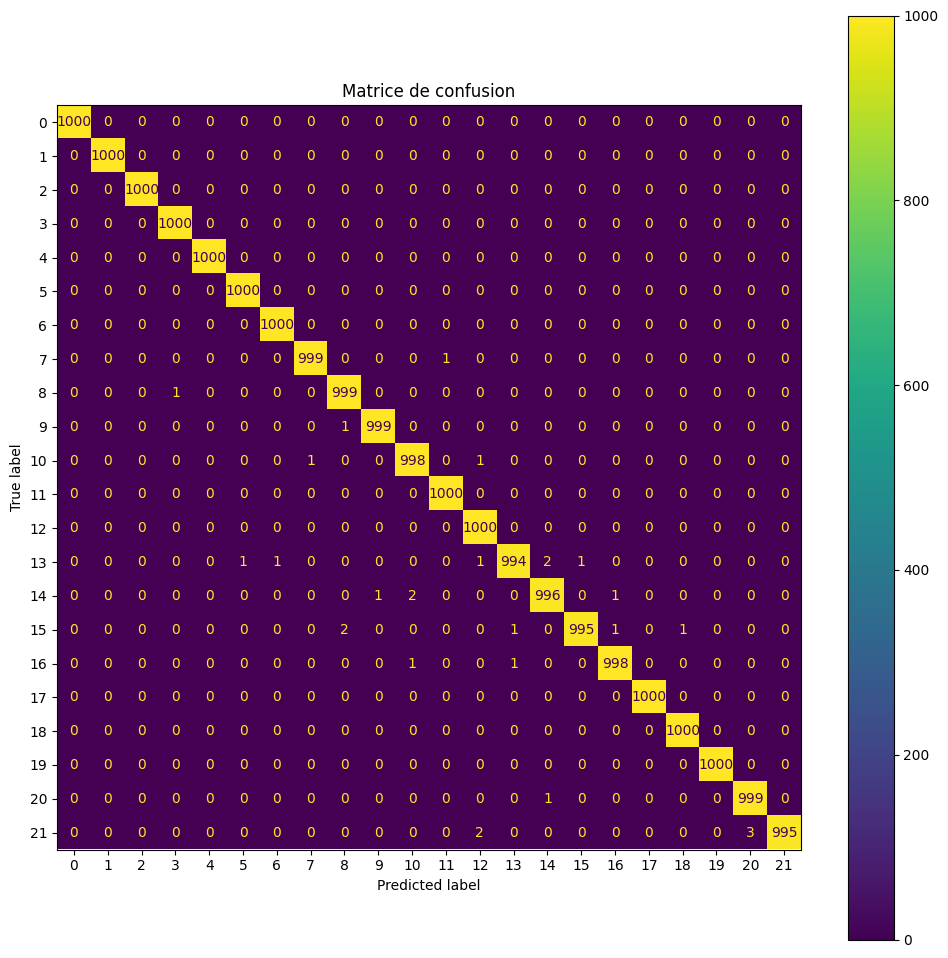

In [5]:


# Évaluation globale
accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy globale :")
print(accuracy)

print("\nClassification report :")
print(classification_report(y_test, y_pred))


# Matrice de confusion
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(12,12))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot(ax=ax)

plt.title("Matrice de confusion")
plt.show()


 Enfin cette partie du code permet d’analyser l’influence du paramètre strength sur les performances du modèle. Le paramètre strength représente l’intensité de la déformation appliquée aux données simulées. Un nouveau DataFrame nommé df_eval est créé afin de regrouper, pour chaque observation du jeu de test, le niveau de déformation (strength), la vraie classe (true) ainsi que la classe prédite par le modèle (pred). Une colonne supplémentaire appelée correct est ensuite ajoutée pour indiquer si la prédiction est correcte ou non.

Les données sont ensuite regroupées selon les différentes valeurs de strength grâce à la fonction groupby, puis l’accuracy moyenne est calculée pour chaque niveau de déformation. Les résultats montrent que les performances du modèle restent extrêmement élevées pour toutes les valeurs de strength, avec des accuracies toujours supérieures à 99,7 %. Lorsque strength = 0, l’accuracy atteint 100 %, ce qui signifie que le modèle classe parfaitement les données sans déformation. Une légère diminution des performances est observée lorsque l’intensité de déformation augmente, notamment pour strength = 0.1, mais cette baisse reste très faible.

Le graphique permet de visualiser l’évolution de l’accuracy en fonction du niveau de déformation. On constate que la courbe reste globalement stable et très proche de 1, ce qui montre que le modèle est robuste face aux déformations appliquées aux profils. Ces résultats indiquent donc que le modèle conserve une excellente capacité de classification même lorsque les données sont modifiées ou bruitées.


Accuracy selon strength :
strength
0.0    1.000000
0.1    0.997506
0.2    0.998598
0.3    0.998396
0.4    0.999107
Name: correct, dtype: float64


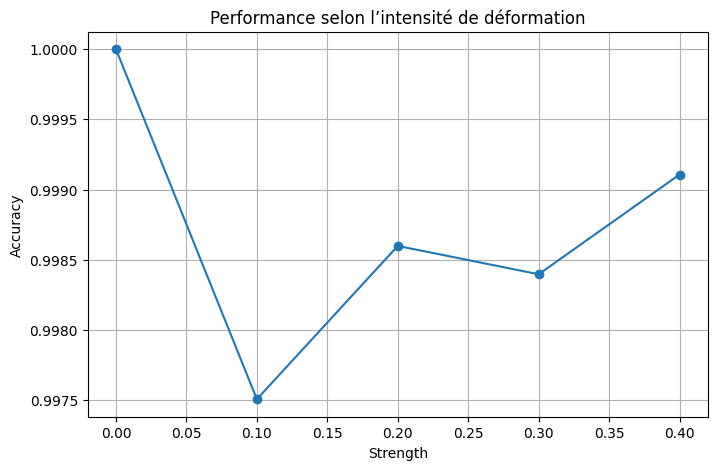

In [6]:
# Étude de l'effet de strength


# dataframe d'évaluation
df_eval = pd.DataFrame({
    "strength": s_test,
    "true": y_test,
    "pred": y_pred
})

# prédiction correcte ?
df_eval["correct"] = (
    df_eval["true"] == df_eval["pred"]
)

# accuracy par niveau de strength
accuracy_strength = (
    df_eval
    .groupby("strength")["correct"]
    .mean()
)

print("\nAccuracy selon strength :")
print(accuracy_strength)


# Graphique accuracy vs strength


plt.figure(figsize=(8,5))

plt.plot(
    accuracy_strength.index,
    accuracy_strength.values,
    marker='o'
)

plt.xlabel("Strength")
plt.ylabel("Accuracy")
plt.title("Performance selon l’intensité de déformation")
plt.grid(True)

plt.show()

## 2: Réduire la dimension des données améliore-t-il les performances dans ce cas?

### Réduction de dimension par PCA

Afin de réduire la dimension des données, une Analyse en Composantes Principales (PCA) a été appliquée aux profils chromosomiques. Cette méthode permet de transformer les 100 variables initiales en un nombre plus faible de composantes principales tout en conservant l’essentiel de l’information contenue dans les données. Le paramètre n_components=0.95 a été choisi afin de conserver 95 % de la variance totale du jeu de données.
Après application de la PCA, les données d’apprentissage passent d’une dimension initiale de 88000×100 à une dimension réduite de 88000×18. Ainsi, seulement 18 composantes principales suffisent à conserver 95 % de l’information présente dans les données initiales. Cette réduction importante suggère que les profils chromosomiques possèdent une structure fortement corrélée et qu’une partie des variables initiales contient des informations redondantes.

Le graphique de la variance expliquée cumulée montre une augmentation progressive de la proportion de variance conservée lorsque le nombre de composantes augmente. La courbe est croissante et tend progressivement vers 1, ce qui est cohérent avec le fonctionnement de la PCA puisque chaque nouvelle composante ajoute une partie supplémentaire de l’information totale. On observe qu’à partir d’environ 18 composantes, la variance expliquée cumulée atteint 95 %, ce qui justifie le choix retenu pour la réduction de dimension.

Dimensions avant PCA : (88000, 100)
Dimensions après PCA : (88000, 18)
Nombre de composantes conservées :
18


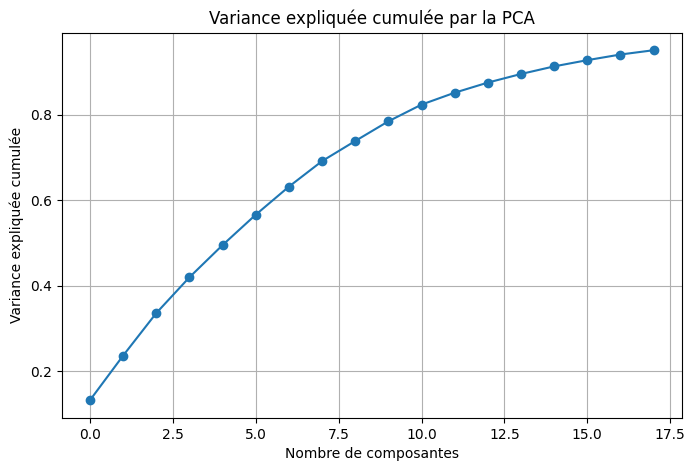

In [7]:
from sklearn.decomposition import PCA

# Réduction de dimension avec PCA


# On conserve 95 % de la variance expliquée
pca = PCA(n_components=0.95)

# apprentissage de la PCA sur les données train
X_train_pca = pca.fit_transform(X_train)

# transformation des données test
X_test_pca = pca.transform(X_test)

# dimensions avant/après réduction
print("Dimensions avant PCA :", X_train.shape)
print("Dimensions après PCA :", X_train_pca.shape)

# nombre de composantes retenues
print("Nombre de composantes conservées :")
print(pca.n_components_)

# Variance expliquée


# variance expliquée cumulée
cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

plt.figure(figsize=(8,5))

plt.plot(
    cumulative_variance,
    marker='o'
)

plt.xlabel("Nombre de composantes")
plt.ylabel("Variance expliquée cumulée")

plt.title("Variance expliquée cumulée par la PCA")

plt.grid(True)

plt.show()

### Classification Après PCA

Après la réduction de dimension par PCA, une forêt aléatoire est entraînée sur les nouvelles données réduites. Les mêmes paramètres que dans la question précédente sont conservés afin de permettre une comparaison directe entre les performances obtenues avec les données brutes et celles obtenues après réduction de dimension. Le modèle est ensuite entraîné sur l’ensemble d’apprentissage réduit, puis utilisé pour réaliser des prédictions sur l’ensemble de test.

In [8]:
# Construction de la Random Forest
rf_pca = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)


# Entraînement
rf_pca.fit(X_train_pca, y_train)


# Prédictions
y_pred_pca = rf_pca.predict(X_test_pca)

### Evaluation Et Comparaison 

Les performances du modèle utilisant les données réduites par PCA ont ensuite été évaluées sur l’ensemble de test. L’accuracy globale obtenue est d’environ 99,1 %, ce qui montre que la réduction de dimension conserve une très grande partie de l’information utile à la classification. Les métriques du classification report indiquent également des valeurs très élevées de précision, de rappel et de F1-score pour l’ensemble des 22 classes, généralement proches de 0,99 ou 1, ce qui traduit une excellente qualité de classification. La matrice de confusion confirme ces résultats puisque la très grande majorité des observations sont correctement classées, comme l’indiquent les valeurs élevées situées sur la diagonale principale. Pour la plupart des classes, le nombre de bonnes prédictions est proche de 1000, ce qui confirme les excellentes performances du modèle après réduction de dimension par PCA. Les erreurs de classification restent très limitées et concernent principalement certaines classes intermédiaires, notamment autour des classes 9 à 16, où quelques confusions apparaissent entre chromosomes présentant des profils relativement similaires. Cependant, ces erreurs restent peu nombreuses par rapport au nombre total d’observations


Accuracy avec PCA :
0.9911818181818182

Classification report avec PCA :
              precision    recall  f1-score   support

           1       1.00      1.00      1.00      1000
           2       0.99      0.99      0.99      1000
           3       0.99      1.00      1.00      1000
           4       0.99      1.00      1.00      1000
           5       0.99      0.99      0.99      1000
           6       0.99      0.99      0.99      1000
           7       1.00      1.00      1.00      1000
           8       0.98      0.99      0.98      1000
           9       0.98      0.99      0.99      1000
          10       0.99      0.97      0.98      1000
          11       0.99      0.97      0.98      1000
          12       0.99      0.99      0.99      1000
          13       0.98      0.99      0.98      1000
          14       0.99      0.99      0.99      1000
          15       0.99      0.99      0.99      1000
          16       0.99      0.97      0.98      1000
       

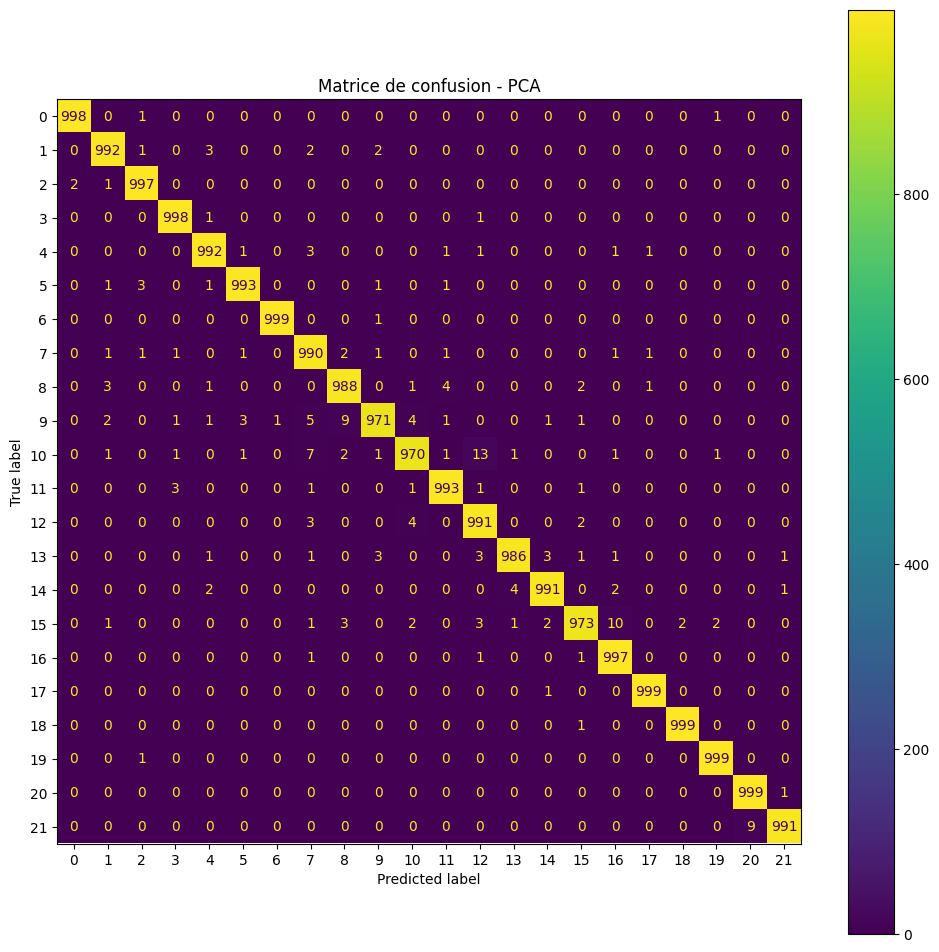

In [9]:
# Évaluation globale
accuracy_pca = accuracy_score(
    y_test,
    y_pred_pca
)

print("\nAccuracy avec PCA :")
print(accuracy_pca)

print("\nClassification report avec PCA :")
print(classification_report(
    y_test,
    y_pred_pca
))


# Matrice de confusion
cm_pca = confusion_matrix(
    y_test,
    y_pred_pca
)

fig, ax = plt.subplots(figsize=(12,12))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_pca
)

disp.plot(ax=ax)

plt.title("Matrice de confusion - PCA")

plt.show()

Une comparaison des performances selon le niveau de déformation (strength) a également été réalisée entre les données brutes et les données réduites par PCA. Les résultats montrent que les performances obtenues avec les données brutes restent légèrement supérieures pour toutes les valeurs de strength. L’écart est particulièrement visible pour strength = 0.1, où l’accuracy avec PCA diminue davantage. Toutefois, les performances restent globalement très élevées même après réduction de dimension, avec des accuracies toujours supérieures à 97 %. Cela indique que la PCA permet de réduire fortement la dimension des données de 100 variables à seulement 18 composantes tout en conservant une excellente capacité de classification. Cependant, cette réduction entraîne une légère perte d’information, ce qui explique les performances légèrement inférieures à celles obtenues avec les données brutes.


Comparaison des performances
----------------------------------
Accuracy données brutes : 0.9987
Accuracy avec PCA      : 0.9912

Accuracy selon strength avec PCA :
strength
0.0    1.000000
0.1    0.976871
0.2    0.990654
0.3    0.992440
0.4    0.995759
Name: correct, dtype: float64


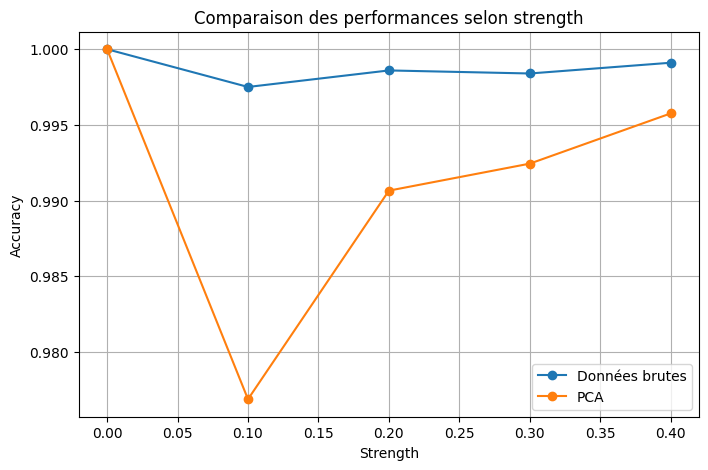

In [10]:
# Comparaison avec les données brutes
print("\nComparaison des performances")
print("----------------------------------")
print(f"Accuracy données brutes : {accuracy:.4f}")
print(f"Accuracy avec PCA      : {accuracy_pca:.4f}")


# Étude de l'effet de strength
df_eval_pca = pd.DataFrame({
    "strength": s_test,
    "true": y_test,
    "pred": y_pred_pca
})

# prédiction correcte ?
df_eval_pca["correct"] = (
    df_eval_pca["true"] == df_eval_pca["pred"]
)

# accuracy par niveau de strength
accuracy_strength_pca = (
    df_eval_pca
    .groupby("strength")["correct"]
    .mean()
)

print("\nAccuracy selon strength avec PCA :")
print(accuracy_strength_pca)


# Graphique accuracy vs strength
plt.figure(figsize=(8,5))

plt.plot(
    accuracy_strength.index,
    accuracy_strength.values,
    marker='o',
    label="Données brutes"
)

plt.plot(
    accuracy_strength_pca.index,
    accuracy_strength_pca.values,
    marker='o',
    label="PCA"
)

plt.xlabel("Strength")
plt.ylabel("Accuracy")

plt.title("Comparaison des performances selon strength")

plt.legend()

plt.grid(True)

plt.show()

## 3: Reprendre la question 1 en classant à partir des décompositions en série de Fourier et/ou en B-spline

Dans cette partie, les profils chromosomiques ne sont plus utilisés directement sous leur forme brute, mais sont représentés à l’aide d’une décomposition en série de Fourier. L’objectif est de considérer chaque profil comme une fonction et de le résumer par un ensemble réduit de coefficients décrivant sa forme générale. La classe Smoothing est utilisée avec l’option fit='fourier' et le paramètre n=10, ce qui permet d’obtenir 2n+1=21 coefficients de Fourier pour chaque chromosome. Les données initiales de dimension 110000×100 sont ainsi transformées en une nouvelle matrice de dimension 110000×21, ce qui réduit fortement le nombre de variables tout en conservant l’information principale du signal.

Une séparation train/test stratifiée est ensuite réalisée afin de conserver les proportions des différentes classes dans les deux ensembles. Une forêt aléatoire est ensuite entraînée sur les coefficients de Fourier à l’aide des mêmes paramètres que dans les questions précédentes afin de permettre une comparaison équitable entre les différentes représentations des données.



In [11]:

# Fourier et B-splines
from smoothing import Smoothing

# Décomposition de Fourier


# Construction des coefficients de Fourier
# n=10 -> 2*n+1 = 21 coefficients

sm_fourier = Smoothing(
    fit='fourier',
    n=10,
    data=X
)

# coefficients de Fourier
X_fourier = sm_fourier.coeffs

print("Dimensions des coefficients de Fourier :")
print(X_fourier.shape)


# Séparation train/test
Xf_train, Xf_test, y_train, y_test, sf_train, sf_test = train_test_split(
    X_fourier,
    y,
    strength,
    test_size=0.2,
    stratify=y,
    random_state=42
)


# Construction de la Random Forest
rf_fourier = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)


# Entraînement
rf_fourier.fit(Xf_train, y_train)


# Prédictions
y_pred_fourier = rf_fourier.predict(Xf_test)


Dimensions des coefficients de Fourier :
(110000, 21)


Les performances obtenues restent très élevées malgré la réduction importante de dimension. L’accuracy globale atteint environ 98,9 %, ce qui montre que les coefficients de Fourier conservent une grande partie de l’information nécessaire à la classification. Les métriques de précision, rappel et F1-score sont proches de 1 pour la majorité des classes, ce qui indique une excellente qualité de prédiction. La matrice de confusion confirme également que la plupart des chromosomes sont correctement classés, même si quelques erreurs supplémentaires apparaissent par rapport aux données brutes.

L’étude des performances selon le paramètre strength montre que le modèle reste globalement robuste face aux déformations. Lorsque strength = 0, l’accuracy est parfaite. Une baisse plus marquée est cependant observée pour strength = 0.1, où l’accuracy descend à environ 97,1 %, avant de remonter progressivement pour les valeurs plus élevées de déformation. Le graphique comparatif montre que les performances obtenues avec les coefficients de Fourier restent légèrement inférieures à celles obtenues avec les données brutes et également un peu inférieures à celles obtenues avec la PCA. Cela suggère que la décomposition de Fourier permet une forte compression des données tout en conservant de bonnes performances de classification, mais qu’une partie de l’information discriminante est perdue lors de cette représentation fonctionnelle


Accuracy avec Fourier :
0.9888181818181818

Classification report Fourier :
              precision    recall  f1-score   support

           1       0.99      0.99      0.99      1000
           2       0.99      0.99      0.99      1000
           3       1.00      1.00      1.00      1000
           4       0.99      1.00      0.99      1000
           5       0.99      0.99      0.99      1000
           6       0.99      0.99      0.99      1000
           7       1.00      1.00      1.00      1000
           8       0.98      0.99      0.98      1000
           9       0.98      0.98      0.98      1000
          10       0.99      0.97      0.98      1000
          11       0.98      0.96      0.97      1000
          12       0.99      0.99      0.99      1000
          13       0.98      0.99      0.98      1000
          14       0.99      0.99      0.99      1000
          15       0.99      0.99      0.99      1000
          16       0.99      0.96      0.98      1000
    

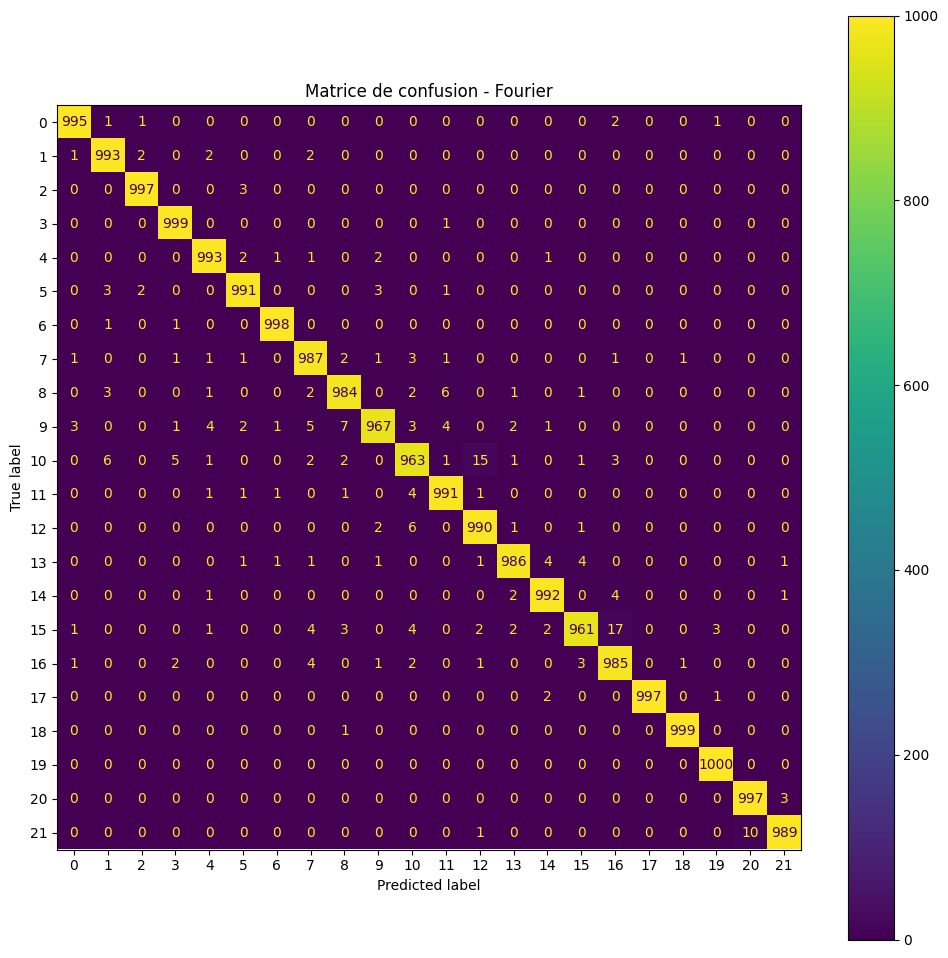


Accuracy selon strength - Fourier :
strength
0.0    1.000000
0.1    0.970975
0.2    0.986682
0.3    0.992669
0.4    0.993527
Name: correct, dtype: float64


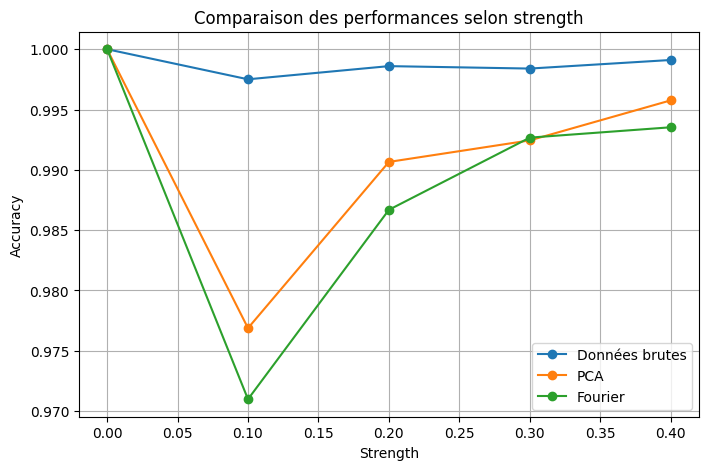

In [12]:
# Évaluation globale
accuracy_fourier = accuracy_score(
    y_test,
    y_pred_fourier
)

print("\nAccuracy avec Fourier :")
print(accuracy_fourier)

print("\nClassification report Fourier :")
print(classification_report(
    y_test,
    y_pred_fourier
))


# Matrice de confusion
cm_fourier = confusion_matrix(
    y_test,
    y_pred_fourier
)

fig, ax = plt.subplots(figsize=(12,12))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_fourier
)

disp.plot(ax=ax)

plt.title("Matrice de confusion - Fourier")

plt.show()


# Accuracy selon strength
df_eval_fourier = pd.DataFrame({
    "strength": sf_test,
    "true": y_test,
    "pred": y_pred_fourier
})

df_eval_fourier["correct"] = (
    df_eval_fourier["true"] ==
    df_eval_fourier["pred"]
)

accuracy_strength_fourier = (
    df_eval_fourier
    .groupby("strength")["correct"]
    .mean()
)

print("\nAccuracy selon strength - Fourier :")
print(accuracy_strength_fourier)


# Graphique accuracy vs strength
plt.figure(figsize=(8,5))

plt.plot(
    accuracy_strength.index,
    accuracy_strength.values,
    marker='o',
    label="Données brutes"
)

plt.plot(
    accuracy_strength_pca.index,
    accuracy_strength_pca.values,
    marker='o',
    label="PCA"
)

plt.plot(
    accuracy_strength_fourier.index,
    accuracy_strength_fourier.values,
    marker='o',
    label="Fourier"
)

plt.xlabel("Strength")
plt.ylabel("Accuracy")

plt.title("Comparaison des performances selon strength")

plt.legend()

plt.grid(True)

plt.show()


Les profils chromosomiques sont ici représentés à l’aide d’une décomposition en B-splines afin de résumer chaque signal par un nombre réduit de coefficients décrivant sa forme générale. La méthode Smoothing est utilisée avec l’option fit='bspline', un paramètre de lissage fixé à 0.3 et 20 fonctions de base (terms=20). Chaque chromosome est alors décrit par 20 coefficients au lieu des 100 valeurs initiales du profil. Les données passent ainsi d’une dimension 110000×100 à une dimension 110000×20, ce qui permet une réduction importante de dimension tout en conservant les principales caractéristiques des signaux.

Les données sont ensuite séparées en ensembles d’apprentissage et de test à l’aide d’un échantillonnage stratifié. Une forêt aléatoire est entraînée sur les coefficients B-splines avec les mêmes paramètres que dans les expériences précédentes afin de comparer les différentes méthodes dans des conditions identiques.

In [13]:

#  Décomposition B-spline


sm_bspline = Smoothing(
    fit='bspline',
    smoothing_str=.3,
    terms=20,
    data=X
)

# coefficients B-spline
# coefficients B-spline
X_bspline = np.array(sm_bspline.coeffs)

print("\nDimensions des coefficients B-spline :")
print(X_bspline.shape)


#  Séparation train/test
Xb_train, Xb_test, y_train, y_test, sb_train, sb_test = train_test_split(
    X_bspline,
    y,
    strength,
    test_size=0.2,
    stratify=y,
    random_state=42
)


# Construction de la Random Forest
rf_bspline = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)


#  Entraînement
rf_bspline.fit(Xb_train, y_train)


#  Prédictions
y_pred_bspline = rf_bspline.predict(Xb_test)



Dimensions des coefficients B-spline :
(110000, 20)


Les performances obtenues sont excellentes. L’accuracy globale atteint environ 99,8 %, soit un niveau très proche de celui obtenu avec les données brutes. Les scores de précision, rappel et F1-score sont pratiquement égaux à 1 pour l’ensemble des classes, ce qui montre que la représentation en B-splines conserve presque toute l’information utile à la classification. La matrice de confusion confirme ces résultats puisque la quasi-totalité des observations est correctement classée, avec seulement quelques erreurs isolées entre certaines classes proches.
L’analyse des performances selon le niveau de déformation strength montre également que le modèle reste très robuste face aux perturbations appliquées aux profils. L’accuracy est parfaite lorsque strength = 0, puis reste supérieure à 99,3 % pour toutes les autres valeurs de déformation. Les résultats obtenus avec les B-splines sont donc meilleurs que ceux obtenus avec la PCA et avec la décomposition de Fourier, tout en utilisant un nombre réduit de variables. Cette méthode apparaît ainsi comme une représentation particulièrement efficace des profils chromosomiques pour la tâche de classification.


Accuracy avec B-spline :
0.9979545454545454

Classification report B-spline :
              precision    recall  f1-score   support

           1       1.00      1.00      1.00      1000
           2       1.00      1.00      1.00      1000
           3       1.00      1.00      1.00      1000
           4       1.00      1.00      1.00      1000
           5       1.00      1.00      1.00      1000
           6       1.00      1.00      1.00      1000
           7       1.00      1.00      1.00      1000
           8       0.99      1.00      1.00      1000
           9       1.00      1.00      1.00      1000
          10       1.00      1.00      1.00      1000
          11       1.00      0.99      1.00      1000
          12       1.00      1.00      1.00      1000
          13       1.00      1.00      1.00      1000
          14       0.99      0.99      0.99      1000
          15       0.99      0.99      0.99      1000
          16       1.00      0.99      1.00      1000
  

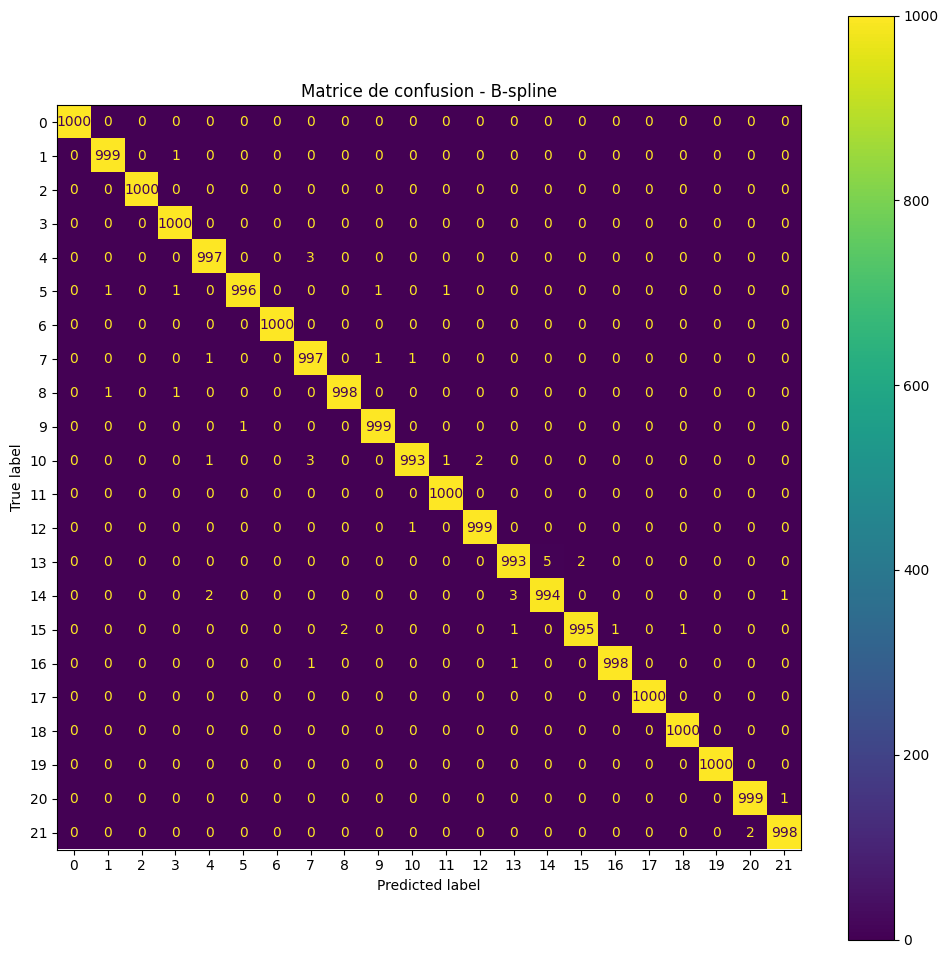


Accuracy selon strength - B-spline :
strength
0.0    1.000000
0.1    0.993651
0.2    0.998131
0.3    0.998396
0.4    0.999554
Name: correct, dtype: float64


In [14]:

#  Évaluation globale
accuracy_bspline = accuracy_score(
    y_test,
    y_pred_bspline
)

print("\nAccuracy avec B-spline :")
print(accuracy_bspline)

print("\nClassification report B-spline :")
print(classification_report(
    y_test,
    y_pred_bspline
))


# Matrice de confusion
cm_bspline = confusion_matrix(
    y_test,
    y_pred_bspline
)

fig, ax = plt.subplots(figsize=(12,12))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_bspline
)

disp.plot(ax=ax)

plt.title("Matrice de confusion - B-spline")

plt.show()


# Accuracy selon strength
df_eval_bspline = pd.DataFrame({
    "strength": sb_test,
    "true": y_test,
    "pred": y_pred_bspline
})

df_eval_bspline["correct"] = (
    df_eval_bspline["true"] ==
    df_eval_bspline["pred"]
)

accuracy_strength_bspline = (
    df_eval_bspline
    .groupby("strength")["correct"]
    .mean()
)

print("\nAccuracy selon strength - B-spline :")
print(accuracy_strength_bspline)

Enfin le graphique compare l’évolution des performances des différentes méthodes en fonction du niveau de déformation des profils. Les données brutes obtiennent les meilleurs résultats avec une accuracy proche de 99,9 % pour toutes les valeurs de strength. La méthode B-spline fournit également d’excellentes performances, très proches de celles obtenues avec les données brutes. La PCA et la décomposition de Fourier entraînent une baisse plus importante de l’accuracy, en particulier pour les faibles valeurs de strength autour de 0.1. Le tableau récapitulatif confirme ces observations : les données brutes donnent les meilleures performances (0.9987), suivies des B-splines (0.9980), tandis que la PCA (0.9912) et Fourier (0.9888) sont légèrement moins efficaces. Ces résultats montrent que les B-splines permettent de réduire la dimension des données tout en conservant presque toute l’information utile à la classification.

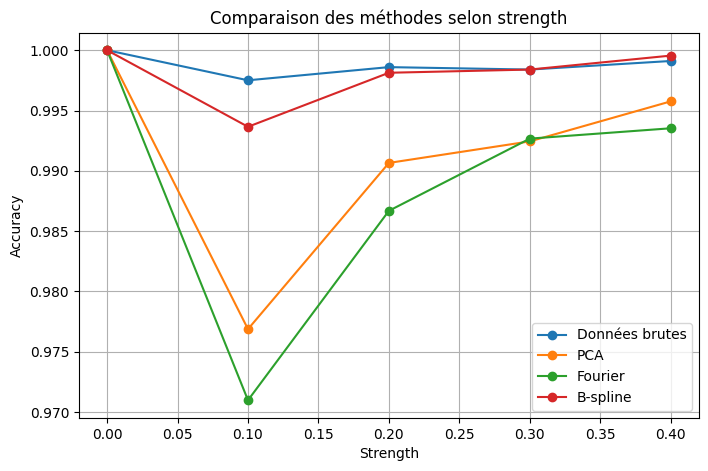


Comparaison finale des accuracies
--------------------------------------
Données brutes : 0.9987
PCA            : 0.9912
Fourier        : 0.9888
B-spline       : 0.9980


In [15]:

#  Comparaison finale


plt.figure(figsize=(8,5))

plt.plot(
    accuracy_strength.index,
    accuracy_strength.values,
    marker='o',
    label="Données brutes"
)

plt.plot(
    accuracy_strength_pca.index,
    accuracy_strength_pca.values,
    marker='o',
    label="PCA"
)

plt.plot(
    accuracy_strength_fourier.index,
    accuracy_strength_fourier.values,
    marker='o',
    label="Fourier"
)

plt.plot(
    accuracy_strength_bspline.index,
    accuracy_strength_bspline.values,
    marker='o',
    label="B-spline"
)

plt.xlabel("Strength")
plt.ylabel("Accuracy")

plt.title("Comparaison des méthodes selon strength")

plt.legend()

plt.grid(True)

plt.show()


# Tableau récapitulatif


print("\nComparaison finale des accuracies")
print("--------------------------------------")

print(f"Données brutes : {accuracy:.4f}")
print(f"PCA            : {accuracy_pca:.4f}")
print(f"Fourier        : {accuracy_fourier:.4f}")
print(f"B-spline       : {accuracy_bspline:.4f}")